# PCA: QR directo frente a ampliación a 32 puntos

Diez semillas, 100 pasos uniformes + 10000 de continuación, reconstrucción cada 100 pasos, PCA centrada con media preservada al 95%. La dimensión total incluye la media independiente. Se conserva la pérdida histórica datos+PDE+IC, candidatos fijos y ventana de 20 snapshots.

La variante directa toma los k pivotes de QR sobre la base ortonormal transpuesta y completa con 128−k puntos Sobol. La referencia toma 32 puntos mediante QR + log-det y completa con 96 Sobol. Ambos usan el mismo prefijo Sobol por semilla y paso. Las historias divergen después de la primera selección por la retroalimentación del entrenamiento. No hay poda en este control. Cambian juntos la ampliación y el número de puntos guiados: no puede atribuirse la diferencia únicamente a log-det.

Las referencias PCA de 32 puntos y Sobol se reutilizan del notebook 17; los parámetros de entrenamiento son comunes. Se evalúa el modelo terminal en tiempos de prueba reservados, sin elegir por prueba.

| Método | RMSE medio ± DE | Residuo RMS |
|---|---:|---:|
| QR directo | 0.07715 ± 0.02436 | 0.10882 |
| 32 por QR + log-det | 0.08320 ± 0.01151 | 0.09586 |
| Sobol | 0.05722 ± 0.01961 | 0.31074 |

QR directo mejora frente a 32 puntos en 6/10 semillas; diferencia media RMSE -0.00605. Rango total observado: 3–16, media 12.52.

**Rango**

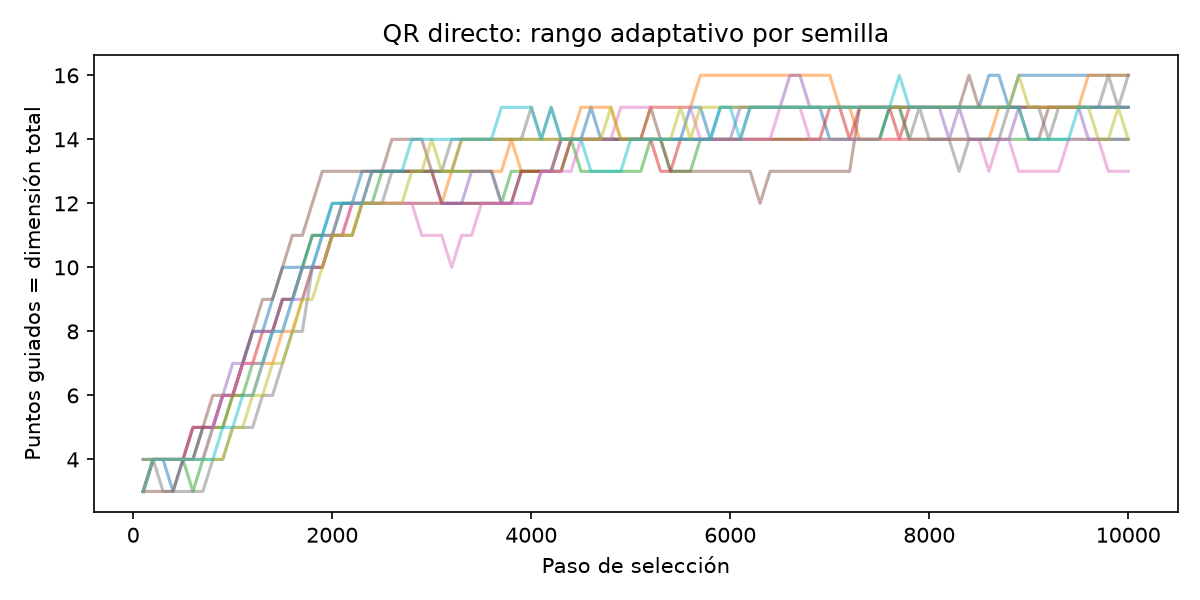

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/direct_qr/pca95_direct_qr_10_seeds_10k_v1/rank.png'), format='png', embed=True))


Reproducir: `python scripts/run_collocation_direct_qr.py`. Corridas completas se reutilizan. Los tiempos no se interpretan como aceleración; esta implementación aún evalúa el diseño ampliado antes de conservar los pivotes directos. El control estudia calidad y presupuesto de puntos.